In [1]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


# REGRESSIONE
from lightgbm import LGBMRegressor
from sklearn.svm import SVR
from sklearn.ensemble import BaggingRegressor

import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from lightgbm import LGBMRegressor
from sklearn.svm import SVR
from sklearn.ensemble import BaggingRegressor

import shap

In [2]:
# dataset
df = pd.read_parquet("df_regression.parquet")


X = df.drop(columns=['SDS-SDS_Total_Raw', "risultati", "id"])
y = df['SDS-SDS_Total_Raw']  # sleep disturbance

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222)

In [3]:
# ==========================================
# Grid Search


# LightGBM
param_grid_lgbm = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [50, 100, 200],
    'num_leaves': [15, 31, 50],
    'max_depth': [-1, 5, 10]
}

grid_lgbm = GridSearchCV(
    estimator=LGBMRegressor(random_state=222),
    param_grid=param_grid_lgbm,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_lgbm.fit(X_train, y_train)


# SVR
pipeline_svr = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

param_grid_svr = {
    'svr__kernel': ['rbf'],
    'svr__C': [0.1, 1.0, 10.0],
    'svr__gamma': ['scale', 'auto', 0.01, 0.1],
    'svr__epsilon': [0.01, 0.1, 0.05]
}

grid_svr = GridSearchCV(
    estimator=pipeline_svr,
    param_grid=param_grid_svr,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_svr.fit(X_train, y_train)

# Bagging
param_grid_bagging = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.5, 0.7, 1.0],
    'max_features': [0.5, 0.7, 1.0]
}

grid_bagging = GridSearchCV(
    estimator=BaggingRegressor(random_state=222),
    param_grid=param_grid_bagging,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_bagging.fit(X_train, y_train)

# Visione Modelli
modelli_ottimizzati = {
    "LightGBM Ottimizzato": grid_lgbm,
    "SVR Ottimizzato": grid_svr,
    "Bagging Ottimizzato": grid_bagging
}

for nome, grid_model in modelli_ottimizzati.items():
    # Il best_estimator_ di GridSearchCV è già fittato sull'intero train set al termine della ricerca
    best_model = grid_model.best_estimator_
    y_pred = best_model.predict(X_test)

    print(f"\n--- {nome} ---")
    print("Migliori Parametri:", grid_model.best_params_)
    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("R2:", r2_score(y_test, y_pred))

Fitting 5 folds for each of 81 candidates, totalling 405 fits


c:\Users\Riccardo\anaconda3\Lib\site-packages\numpy\ma\core.py:2881: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,
c:\Users\Riccardo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Impossibile trovare il file specificato
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Riccardo\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Riccardo\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File 

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000880 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6897
[LightGBM] [Info] Number of data points in the train set: 3351, number of used features: 72
[LightGBM] [Info] Start training from score 41.286034
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits

--- LightGBM Ottimizzato ---
Migliori Parametri: {'learning_rate': 0.05, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 31}
MAE: 6.514070398270338
MSE: 78.94885741907571
R2: 0.10985010736553247

--- SVR Ottimizzato ---
Migliori Parametri: {'svr__C': 1.0, 'svr__epsilon': 0.01, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}
MAE: 6.427631748723881
MSE: 84.82263513569973
R2: 0.04362315013349183

--- Bagging Ottimizzato ---
Migliori Parametri: {'max_features': 0.7, 'max_samples': 0.7, 'n_estimators': 200}
MAE: 6.5277905358385535
MSE

In [9]:
# LightGBM
lgbm = LGBMRegressor(
    learning_rate=0.05,
    n_estimators=100,
    num_leaves=31,  # 31 perchè in un albero decisionale completo 5 Livelli = 2^5 = 32 foglie; limite di 31 viene usato per avere complessità paragonabile a livello 5
    random_state=222
)

lgbm.fit(X_train, y_train)

y_pred_lgbm = lgbm.predict(X_test)

print("LightGBM Model")
print("MAE:", mean_absolute_error(y_test, y_pred_lgbm))
print("MSE:", mean_squared_error(y_test, y_pred_lgbm))
print("R2:", r2_score(y_test, y_pred_lgbm))

feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgbm.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 5 feature per importanza:")
print(feature_importances.head(5))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000914 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6897
[LightGBM] [Info] Number of data points in the train set: 3351, number of used features: 72
[LightGBM] [Info] Start training from score 41.286034
LightGBM Model
MAE: 6.514070398270338
MSE: 78.94885741907571
R2: 0.10985010736553247
Top 5 feature per importanza:
                           Feature  Importance
70  Fitness_Endurance-Tempo_totale         123
4                  CGAS-CGAS_Score         122
17                    FGC-FGC_GSND         112
33                     BIA-BIA_DEE         102
9            Physical-Diastolic_BP          98


In [10]:
# SVR
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = SVR(kernel='rbf', C=1.0, epsilon=0.01, gamma=0.01)

svr.fit(X_train_scaled, y_train)


y_pred_svr_scaled = svr.predict(X_test_scaled)

print("SVR Model (Dati Standardizzati)")
print("MAE:", mean_absolute_error(y_test, y_pred_svr_scaled))
print("MSE:", mean_squared_error(y_test, y_pred_svr_scaled))
print("R2:", r2_score(y_test, y_pred_svr_scaled))

SVR Model (Dati Standardizzati)
MAE: 6.427631748723881
MSE: 84.82263513569973
R2: 0.04362315013349183


In [11]:
# BaggingRegressor
bagging = BaggingRegressor(
    n_estimators=200,
    max_samples=0.7,
    max_features=0.7,
    random_state=222
)


bagging.fit(X_train, y_train)

y_pred_bagging = bagging.predict(X_test)

print("BaggingRegressor Model")
print("MAE:", mean_absolute_error(y_test, y_pred_bagging))
print("MSE:", mean_squared_error(y_test, y_pred_bagging))
print("R2:", r2_score(y_test, y_pred_bagging))

BaggingRegressor Model
MAE: 6.5277905358385535
MSE: 78.76109581593597
R2: 0.11196712306835044


Tabella Riassuntiva dei Risultati:
 Modello      MAE       MSE       R2
LightGBM 6.514070 78.948857 0.109850
     SVR 6.427632 84.822635 0.043623
 Bagging 6.527791 78.761096 0.111967


C:\Users\Riccardo\AppData\Local\Temp\ipykernel_15120\3276914149.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=df_risultati,
C:\Users\Riccardo\AppData\Local\Temp\ipykernel_15120\3276914149.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=df_risultati,
C:\Users\Riccardo\AppData\Local\Temp\ipykernel_15120\3276914149.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2], data=df_risultati,


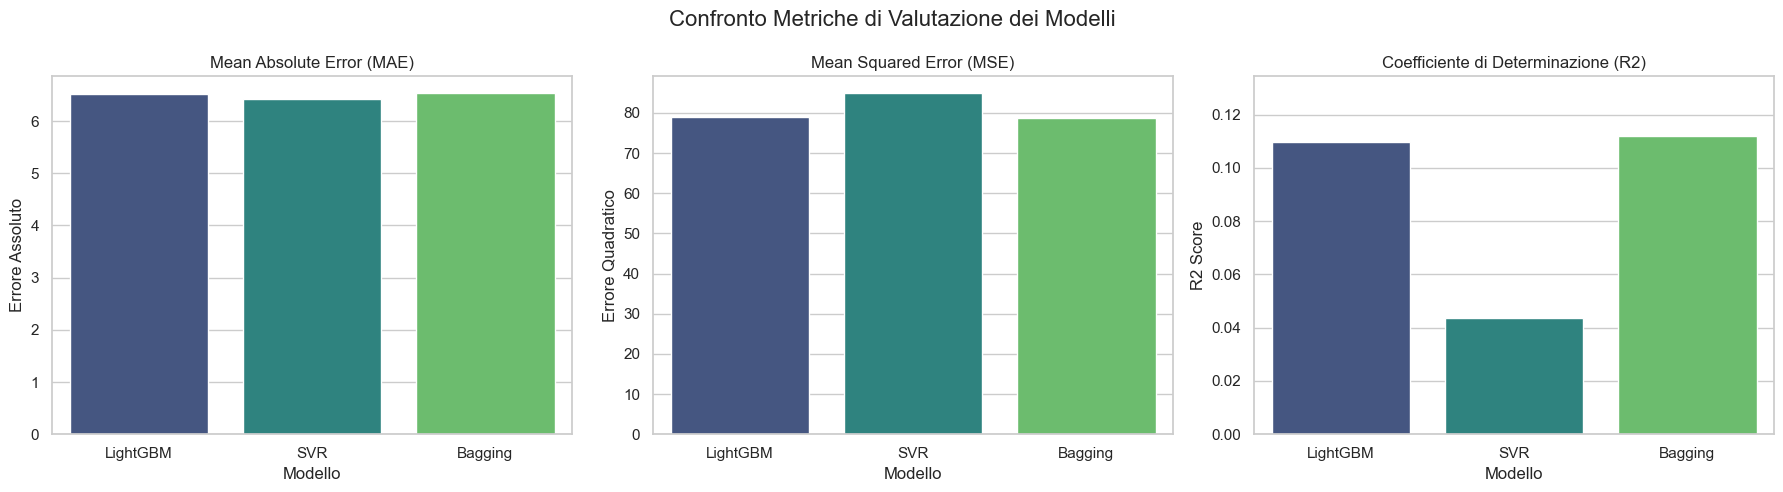

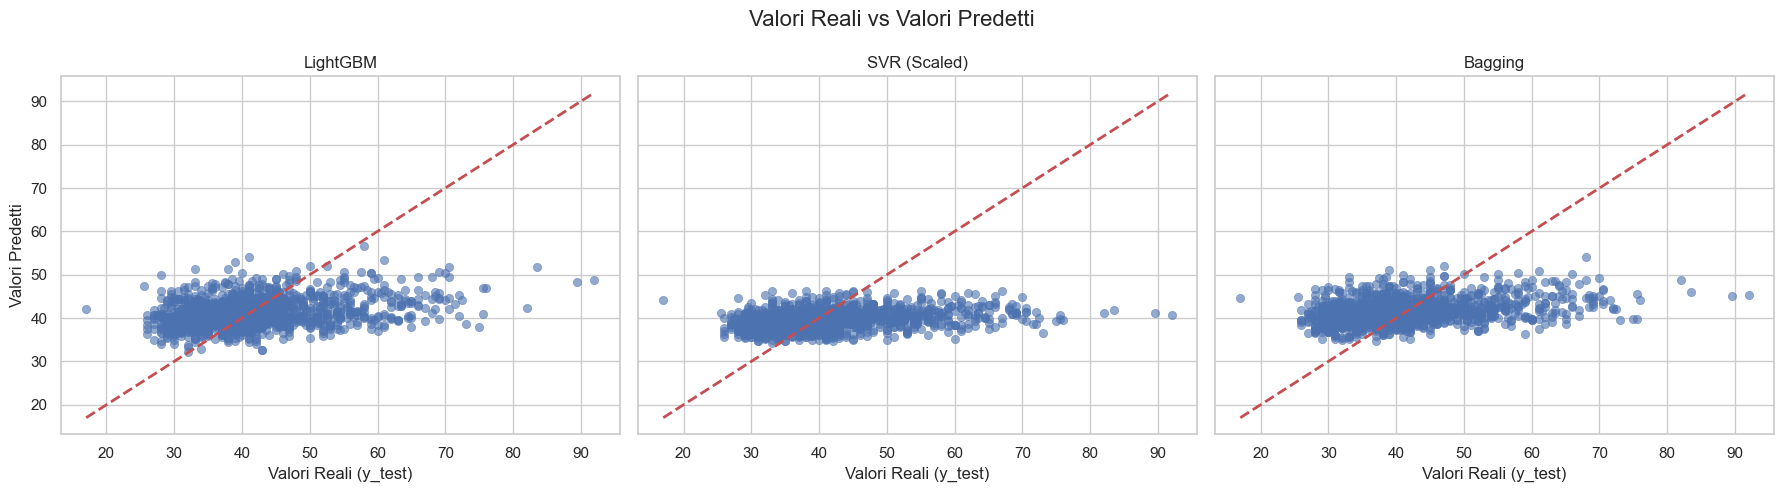

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Costruzione del DataFrame con le metriche dei tre modelli
risultati = {
    'Modello': ['LightGBM', 'SVR', 'Bagging'],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lgbm),
        mean_absolute_error(y_test, y_pred_svr_scaled),
        mean_absolute_error(y_test, y_pred_bagging)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred_lgbm),
        mean_squared_error(y_test, y_pred_svr_scaled),
        mean_squared_error(y_test, y_pred_bagging)
    ],
    'R2': [
        r2_score(y_test, y_pred_lgbm),
        r2_score(y_test, y_pred_svr_scaled),
        r2_score(y_test, y_pred_bagging)
    ]
}

df_risultati = pd.DataFrame(risultati)
print("Tabella Riassuntiva dei Risultati:")
print(df_risultati.to_string(index=False))

# 2. Configurazione dello stile dei grafici
sns.set_theme(style="whitegrid")

# 3. Grafici a barre per il confronto delle metriche
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confronto Metriche di Valutazione dei Modelli', fontsize=16)

# Grafico MAE
sns.barplot(ax=axes[0], data=df_risultati,
            x='Modello', y='MAE', palette='viridis')
axes[0].set_title('Mean Absolute Error (MAE)')
axes[0].set_ylabel('Errore Assoluto')

# Grafico MSE
sns.barplot(ax=axes[1], data=df_risultati,
            x='Modello', y='MSE', palette='viridis')
axes[1].set_title('Mean Squared Error (MSE)')
axes[1].set_ylabel('Errore Quadratico')

# Grafico R2
sns.barplot(ax=axes[2], data=df_risultati,
            x='Modello', y='R2', palette='viridis')
axes[2].set_title('Coefficiente di Determinazione (R2)')
axes[2].set_ylabel('R2 Score')
axes[2].set_ylim(0, max(df_risultati['R2']) * 1.2)  # Aggiusta l'asse Y per R2

plt.tight_layout()
plt.show()

# 4. Scatter plot per confrontare i valori reali con quelli predetti
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle('Valori Reali vs Valori Predetti', fontsize=16)

predizioni = [
    (y_pred_lgbm, 'LightGBM'),
    (y_pred_svr_scaled, 'SVR (Scaled)'),
    (y_pred_bagging, 'Bagging')
]

for i, (y_pred, nome_modello) in enumerate(predizioni):
    sns.scatterplot(ax=axes[i], x=y_test, y=y_pred, alpha=0.6, edgecolor=None)
    # Linea ideale (Predetto = Reale)
    axes[i].plot([y_test.min(), y_test.max()], [
                 y_test.min(), y_test.max()], 'r--', lw=2)
    axes[i].set_title(nome_modello)
    axes[i].set_xlabel('Valori Reali (y_test)')
    if i == 0:
        axes[i].set_ylabel('Valori Predetti')

plt.tight_layout()
plt.show()

In [8]:
'''# SHAP su LGBM

# 1. Inizializzazione dell'Explainer
# TreeExplainer è progettato specificamente per ottimizzare il calcolo SHAP su modelli ad albero
explainer = shap.TreeExplainer(lgbm)

# 2. Calcolo dei valori SHAP
# Si utilizza il test set per valutare l'impatto delle variabili su dati non visti durante l'addestramento
shap_values = explainer.shap_values(X_test)

# ==========================================
# SPIEGAZIONE GLOBALE (Global Explainability)
# ==========================================

# Summary Plot (Dot): Mostra la distribuzione dell'impatto di ciascuna variabile.
# I colori indicano il valore reale della feature (alto/basso), la posizione sull'asse X indica
# l'impatto sulla predizione (sii).
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot - Impatto Globale ed Effetto delle Feature")
plt.tight_layout()
plt.show()

# Summary Plot (Bar): Fornisce una classifica classica dell'importanza delle variabili
# basata sulla media del valore assoluto dei valori SHAP.
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot - Importanza Media Assoluta")
plt.tight_layout()
plt.show()

# ==========================================
# SPIEGAZIONE LOCALE (Local Explainability)
# ==========================================

# Selezione di una singola osservazione dal set di test per spiegarne la predizione specifica
osservazione_idx = 22
dati_osservazione = X_test.iloc[osservazione_idx]

# Creazione dell'oggetto Explanation richiesto dalla nuova API di SHAP per grafici avanzati
shap_exp = shap.Explanation(
    values=shap_values[osservazione_idx],
    base_values=explainer.expected_value,
    data=dati_osservazione.values,
    feature_names=X_test.columns
)

# Waterfall Plot: Illustra il percorso decisionale partendo dal valore base (media di tutte le predizioni)
# fino al valore effettivamente predetto per questa singola istanza, quantificando il contributo
# positivo o negativo di ogni singola variabile.
plt.figure()
shap.plots.waterfall(shap_exp, max_display=10, show=False)
plt.title(
    f"SHAP Waterfall Plot - Spiegazione Singola Predizione (Indice {osservazione_idx})")
plt.tight_layout()
plt.show()'''

'# SHAP su LGBM\n\n# 1. Inizializzazione dell\'Explainer\n# TreeExplainer è progettato specificamente per ottimizzare il calcolo SHAP su modelli ad albero\nexplainer = shap.TreeExplainer(lgbm)\n\n# 2. Calcolo dei valori SHAP\n# Si utilizza il test set per valutare l\'impatto delle variabili su dati non visti durante l\'addestramento\nshap_values = explainer.shap_values(X_test)\n\n# ==========================================\n# SPIEGAZIONE GLOBALE (Global Explainability)\n# ==========================================\n\n# Summary Plot (Dot): Mostra la distribuzione dell\'impatto di ciascuna variabile.\n# I colori indicano il valore reale della feature (alto/basso), la posizione sull\'asse X indica\n# l\'impatto sulla predizione (sii).\nplt.figure()\nshap.summary_plot(shap_values, X_test, plot_type="dot", show=False)\nplt.title("SHAP Summary Plot - Impatto Globale ed Effetto delle Feature")\nplt.tight_layout()\nplt.show()\n\n# Summary Plot (Bar): Fornisce una classifica classica dell\'imp